# 1 · Reproducing the results

This notebook has two parts.

**Part A (computed live in this notebook)** downloads the two released checkpoints from the Hugging Face Hub and
re-runs the full evaluation protocol on the 360 held-out NEU-DET images.

**Part B (read from `results/`)** builds the results table from the stored evaluation of the training runs (5 seeds per model).
Notebook 3 shows how to re-run them.

Every cell output below was produced by executing this notebook from top to bottom.

In [1]:
import json, os, sys, warnings
from pathlib import Path
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)                                   # all paths below are relative to the repository root
from defect_aware_mae import data, evaluate, hub, report
from defect_aware_mae.data import CLASSES, load_split
from defect_aware_mae.models import embed, load_encoder
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
pd.set_option("display.max_colwidth", 90); pd.set_option("display.width", 220)
print("repo:", ROOT.name, "| device:", DEVICE, "| torch", torch.__version__)

repo: defect-aware-MAE | device: cuda | torch 2.4.0+cu121


## Data

`scripts/prepare_data.py` unpacks NEU-DET and builds the preprocessed arrays (CLAHE, resize to 224×224). The md5
check confirms the inputs are byte-identical to the ones used for the released results.

In [2]:
Xtr, ytr, _ = load_split("train", verify=True); Xva, yva, _ = load_split("validation", verify=True)
print("train", Xtr.shape, "| validation", Xva.shape, "| classes", CLASSES)
print("checksums match the reference; pretraining used the train split only")

train (1440, 224, 224) | validation (360, 224, 224) | classes ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']
checksums match the reference; pretraining used the train split only


## Part A · Live evaluation of the released weights

Protocol (`defect_aware_mae/evaluate.py`): frozen encoder → standardise features → cluster the held-out images.
Labels are used only to score the clusters (Hungarian-matched accuracy, NMI, ARI); the silhouette needs no labels.

In [3]:
live = {}
for name in ("defect_aware_mae", "simclr"):
    path, mode = hub.download(name)
    live[name] = evaluate.run(path, mode, device=DEVICE)
    v = live[name]["heldout_transductive"]["umap2_ward_v1cfg"]
    print(f"{name:17s} readout={mode}: acc {100*v['acc']:.2f}  NMI {v['nmi']:.3f}  ARI {v['ari']:.3f}  silhouette {v['sil']:.3f}")

defect_aware_mae  readout=mid: acc 98.33  NMI 0.963  ARI 0.961  silhouette 0.833


simclr            readout=cls: acc 98.06  NMI 0.950  ARI 0.954  silhouette 0.724


In [4]:
# live numbers next to the numbers stored when these exact checkpoints were trained (results/runs/final_*)
stored = {"defect_aware_mae": ("final_mae_hog_energy_dec2_ep1600_s0", "mid"), "simclr": ("final_simclr_lr1.5e-4_s0", "cls")}
rows = []
for name, (tag, mode) in stored.items():
    s = report.load_run(tag, mode)
    for src, r in (("live (this notebook)", live[name]), ("stored (training machine)", s)):
        rows.append({"Checkpoint": name, "Source": src, **{m: round(report.METRICS[m](r), 3) for m in report.MAIN_METRICS}})
pd.DataFrame(rows).set_index(["Checkpoint", "Source"]).T

Checkpoint            defect_aware_mae                                         simclr                          
Source            live (this notebook) stored (training machine) live (this notebook) stored (training machine)
Acc (UMAP+Ward)                 98.333                    98.333               98.056                    98.333
NMI                              0.963                     0.963                0.950                     0.955
ARI                              0.961                     0.961                0.954                     0.961
Silhouette (UMAP)                0.833                     0.827                0.724                     0.738

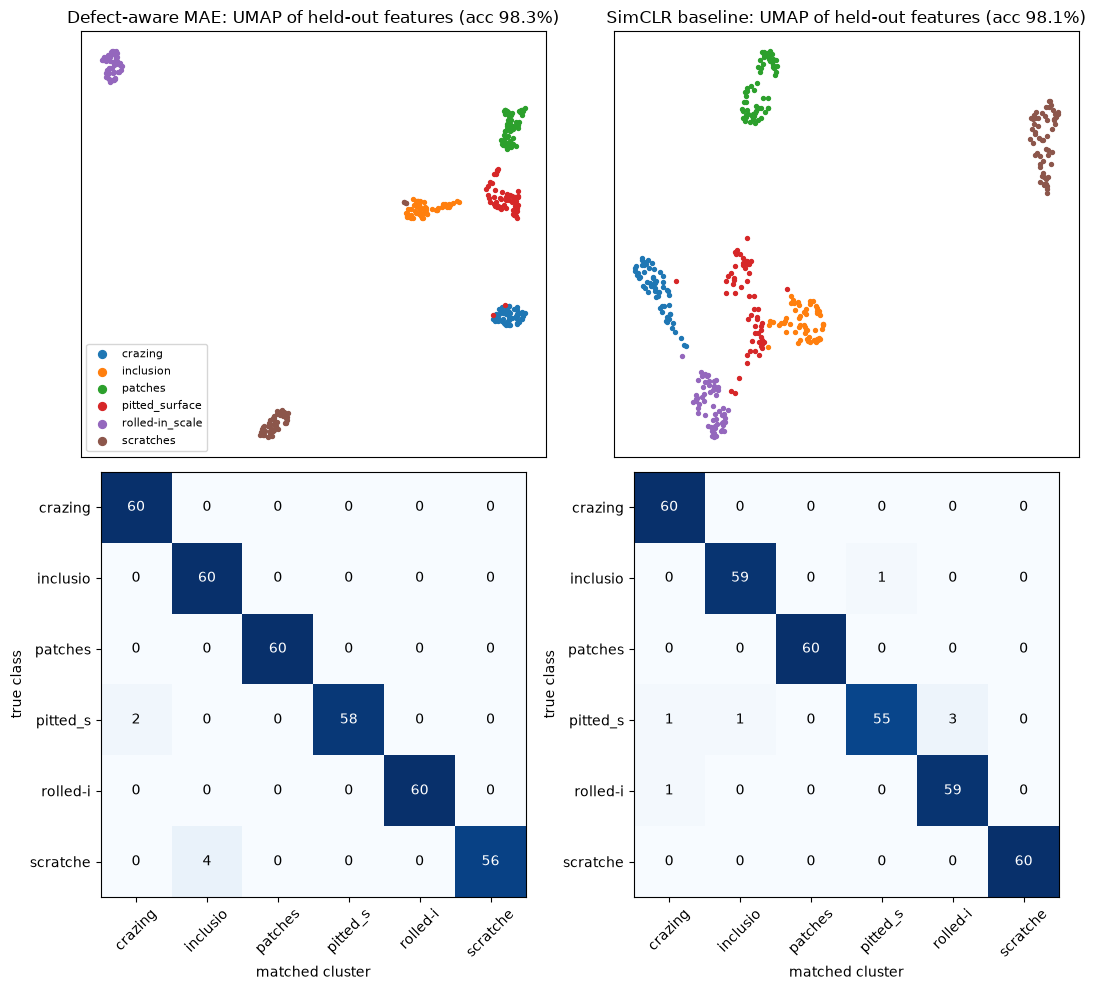

In [5]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import confusion_matrix
fig, ax = plt.subplots(2, 2, figsize=(11, 10))
for j, (name, title) in enumerate((("defect_aware_mae", "Defect-aware MAE"), ("simclr", "SimCLR baseline"))):
    path, mode = hub.download(name)
    F = embed(load_encoder(path, DEVICE), Xva, mode)
    Z = evaluate.umap2(StandardScaler().fit_transform(F))
    c = evaluate.hungarian_map(yva, AgglomerativeClustering(6).fit_predict(Z))
    for k in range(6): ax[0, j].scatter(*Z[yva == k].T, s=8, label=CLASSES[k])
    ax[0, j].set_title(f"{title}: UMAP of held-out features (acc {100*(c==yva).mean():.1f}%)"); ax[0, j].set_xticks([]); ax[0, j].set_yticks([])
    cm = confusion_matrix(yva, c, labels=range(6)); ax[1, j].imshow(cm, cmap="Blues")
    for a in range(6):
        for b in range(6): ax[1, j].text(b, a, cm[a, b], ha="center", va="center", color="w" if cm[a, b] > 30 else "k")
    ax[1, j].set_xticks(range(6)); ax[1, j].set_yticks(range(6)); ax[1, j].set_xticklabels([s[:8] for s in CLASSES], rotation=45); ax[1, j].set_yticklabels([s[:8] for s in CLASSES])
    ax[1, j].set_xlabel("matched cluster"); ax[1, j].set_ylabel("true class")
ax[0, 0].legend(fontsize=8, markerscale=2); plt.tight_layout(); plt.savefig("figures/umap_confusion.png", dpi=160); plt.show()

## Part B · Results table from the stored runs

Mean ± std over 5 seeds on the held-out split (`results/runs/<tag>/eval.json`; runs listed in `configs/groups.json`).

In [6]:
G = json.load(open("configs/groups.json")); names = list(G)
MAE, SIM = names[0], names[1]
report.table({k: G[k] for k in (MAE, SIM)}).set_index("Model").T

Model,"Defect-aware MAE (final): HOG + defect masking + strong aug, 2-layer decoder, 1600 ep","SimCLR baseline (lr 1.5e-4, 800 ep)"
Seeds,5,5
Readout,mid,cls
Acc (UMAP+Ward),98.6 ± 0.2,97.8 ± 1.3
NMI,0.968 ± 0.003,0.955 ± 0.021
ARI,0.967 ± 0.004,0.951 ± 0.027
Silhouette (UMAP),0.838 ± 0.019,0.736 ± 0.019


### Training curves (5 seeds)

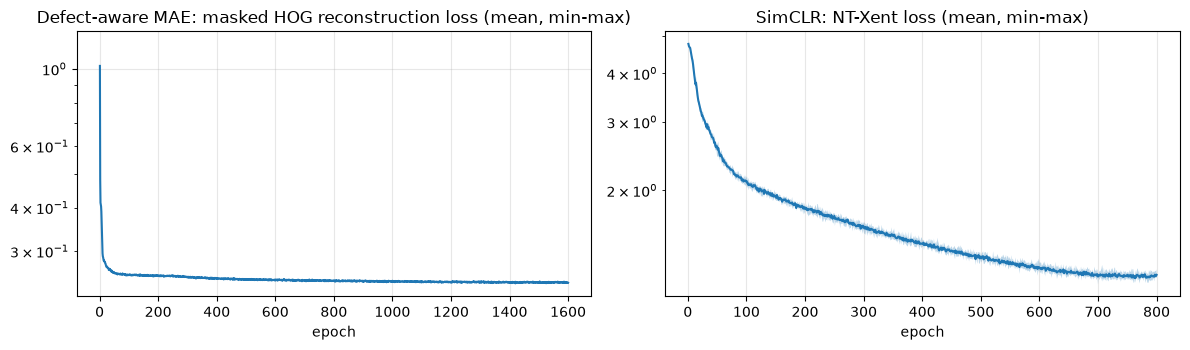

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for a, (g, key, t) in zip(ax, ((MAE, "rec", "Defect-aware MAE: masked HOG reconstruction loss"), (SIM, "nce", "SimCLR: NT-Xent loss"))):
    H = np.array([[e[key] for e in json.load(open(f"results/runs/{tag}/history.json"))] for tag in G[g]["tags"]]); x = np.arange(1, H.shape[1] + 1)
    a.plot(x, H.mean(0)); a.fill_between(x, H.min(0), H.max(0), alpha=.3); a.set_yscale("log"); a.set_xlabel("epoch"); a.set_title(t + " (mean, min-max)"); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig("figures/training_curves.png", dpi=160); plt.show()

## Summary

- **Accuracy:** the Defect-aware MAE reaches 98.6 ± 0.2% held-out clustering accuracy (5 seeds), with very low
  variance across seeds.
- **Cluster quality:** its silhouette is clearly higher than the contrastive baseline's, in UMAP space and in
  PCA space.